<span style="font-weight: bold; font-size: 50px; color: rgb(133, 199, 12);"> Temporal signals analysis : </span> <br>
<span style="font-size: 35px"> Comparison of temporal signals (A-scan) of ceramics from different compositions </span>

# <span style="font-size: 35px"> <strong>Step 1:</strong> Creating and saving ROI for all samples

In [1]:
import sys 
import os

from Sources.LoadData_tprj import *
from Sources import process_list

# file_path = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CTTC_ceramics_CarnotArts_AAPG.tprj"
file_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CTTC_ceramics_CarnotArts_AAPG.tprj"

keys = get_all_available_measurements(file_path)
for key in keys: print(key)

14_composite_20-percent_poro
13_Oxyde-2_raw_no_porogene
12_Oxyde-2_no_porogene_20-percent_poro
11_Oxyde-7_porogene_pression-P2_with_porogene
1_Oxyde-1_no_porogene_0-percent_porosity
10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene
9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene
8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene
7_Oxyde-5_raw_no_porogene
6_Oxyde-5_no_porogene_0-percent_poro
5_Oxyde-4_raw_no_porogene
3_Oxyde-3_raw_no_porogene
4_Oxyde-4_no_porogene_0-percent_poro
3_Oxyde-3_raw_no_porogene_no_focus
2_Oxyde-3_no_porogene_0-percent_porosity
1_Oxyde-1_no_porogene_0-percent_porosity_old_holder


In [26]:
import h5py

file_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CTTC_ceramics_CarnotArts_AAPG.tprj"

# save_path = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files"
save_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CSV_files"

save = True

with h5py.File(f'{file_path}', 'r') as file:
    measurements = file['TerapulseDocument']['Measurements']

    # Only keeping the last reference as the overall reference data
    ref_key = list(measurements['Ref Data'].keys())[0]
    ref = pd.DataFrame(measurements['Ref Data'][ref_key]['sample']['ydata'][:])
    time_axis = pd.DataFrame(measurements['Ref Data'][ref_key]['sample']['xdata'][:])

    print(f"CSV file will be saved as: {save_path}")
    
    if save:
        ref.T.to_csv(save_path+r'\reference.csv', index=False, header=False)
        time_axis.T.to_csv(save_path+r'\time_axis.csv', index=False, header=False)


# from tqdm import tqdm

# for idx in tqdm(range(len(keys))):
#     name = f"{keys[idx]}.csv"

#     path = os.path.join(save_path, name)
#     print(f"CSV file will be saved as: {path}")

#     measurement = HDF5Handler(file_path).get_data_df('Ref0', 'Ref Data')

CSV file will be saved as: \\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CSV_files


In [ ]:
from tqdm import tqdm

x_shape_list = []
y_shape_list = []
file_list = []

save_path = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files"
# save_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CSV_files"

save = False

for idx in tqdm(range(len(keys))):
    name = f"{keys[idx]}.csv"

    path = os.path.join(save_path, name)
    print(f"CSV file will be saved as: {path}")

    measurement = HDF5Handler(file_path).get_data_df(keys[idx], 'Image Data')

    X,Y,x,y,nx,ny,pattern_x_arranged,pattern_y_arranged = process_list.spacial_correction(measurement[0],measurement[1])
    data_Y_arranged = process_list.data_correction(measurement, X, Y)
    data_X_arranged = process_list.ArrangedData_Xconstant(pattern_x_arranged, pattern_y_arranged, data_Y_arranged)

    x_shape_list.append(x.shape)
    y_shape_list.append(y.shape)
    file_list.append(path)
    
    if save :
        data_X_arranged.T.to_csv(path, index=False, header=False)

  0%|          | 0/16 [00:00<?, ?it/s]


Sample 14_composite_20-percent_poro as been selected - name: 14-20-percent
CSV file will be saved as: F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\14_composite_20-percent_poro.csv


  6%|▋         | 1/16 [00:36<09:01, 36.08s/it]


Sample 13_Oxyde-2_raw_no_porogene as been selected - name: 13-raw
CSV file will be saved as: F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\13_Oxyde-2_raw_no_porogene.csv


 12%|█▎        | 2/16 [00:52<05:41, 24.41s/it]

...

 88%|████████▊ | 14/16 [09:51<00:52, 26.30s/it]


Sample 2_Oxyde-3_no_porogene_0-percent_porosity as been selected - name: 2-no
CSV file will be saved as: F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\2_Oxyde-3_no_porogene_0-percent_porosity.csv


 94%|█████████▍| 15/16 [10:05<00:22, 22.37s/it]


Sample 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder as been selected - name: 1-no
CSV file will be saved as: F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\1_Oxyde-1_no_porogene_0-percent_porosity_old_holder.csv


100%|██████████| 16/16 [11:28<00:00, 43.06s/it]


In [6]:
import numpy as np

prefix_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
# prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

np.save(fr"{prefix_path}/x_shape_list", x_shape_list)
np.save(fr"{prefix_path}/y_shape_list", y_shape_list)
np.save(fr"{prefix_path}/file_list", file_list)

In [7]:
from tqdm import tqdm

prefix_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
# prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

x_shape_list = np.load(fr"{prefix_path}/x_shape_list.npy")
y_shape_list = np.load(fr"{prefix_path}/y_shape_list.npy")
file_list = np.load(fr"{prefix_path}/file_list.npy")

save_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
# save_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"
save = True

ROI_list = []

X_ROI = 15
Y_ROI = 15

for idx in tqdm(range(len(file_list))):
    # loadi into numpy array
    signal_array = np.loadtxt(file_list[idx], delimiter=',')
    signal_array = signal_array[:, :].T

    # Show matrix size
    print(file_list[idx])
    print("array shape:", signal_array.shape)
    print(x_shape_list[idx], x_shape_list[idx][0]*x_shape_list[idx][1])
    print(y_shape_list[idx], y_shape_list[idx][0]*y_shape_list[idx][1])

    datacube = signal_array.reshape(x_shape_list[idx][1], x_shape_list[idx][0], 2048) # If using filtered signal
    # Check size
    print("Final datacube shape (x,y,time):", datacube.shape)



    ROI = datacube[datacube.shape[0]//2-X_ROI:datacube.shape[0]//2+X_ROI,
                datacube.shape[1]//2-Y_ROI:datacube.shape[1]//2+Y_ROI,
                :]

    ROI_list.append(ROI)

ROI_arr = np.array(ROI_list)
if save :
    np.save(rf"{save_path}/ROI_arr", ROI_arr)

  6%|▋         | 1/16 [00:03<00:45,  3.06s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\14_composite_20-percent_poro.csv
array shape: (13456, 2048)
[116 116] 13456
[116 116] 13456
Final datacube shape (x,y,time): (116, 116, 2048)


 12%|█▎        | 2/16 [00:04<00:28,  2.03s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\13_Oxyde-2_raw_no_porogene.csv
array shape: (5776, 2048)
[76 76] 5776
[76 76] 5776
Final datacube shape (x,y,time): (76, 76, 2048)


 19%|█▉        | 3/16 [00:05<00:22,  1.70s/it]

...

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\3_Oxyde-3_raw_no_porogene_no_focus.csv
array shape: (4941, 2048)
[81 61] 4941
[81 61] 4941
Final datacube shape (x,y,time): (61, 81, 2048)


 94%|█████████▍| 15/16 [00:47<00:01,  1.79s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\2_Oxyde-3_no_porogene_0-percent_porosity.csv
array shape: (4941, 2048)
[81 61] 4941
[81 61] 4941
Final datacube shape (x,y,time): (61, 81, 2048)


100%|██████████| 16/16 [00:53<00:00,  3.36s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\1_Oxyde-1_no_porogene_0-percent_porosity_old_holder.csv
array shape: (27693, 2048)
[153 181] 27693
[153 181] 27693
Final datacube shape (x,y,time): (181, 153, 2048)


# <span style="font-size: 35px"> <strong>Step 2:</strong> Loading existing ROI of THz Datacube

In [3]:
import numpy as np

# prefix_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

x_shape_list = np.load(fr"{prefix_path}/x_shape_list.npy")
y_shape_list = np.load(fr"{prefix_path}/y_shape_list.npy")
file_list = np.load(fr"{prefix_path}/file_list.npy")

ROI_arr = np.load(fr"{prefix_path}/ROI_arr.npy")

# <span style="font-size: 35px"> <strong>Study 1:</strong> Temporal A-scan comparison

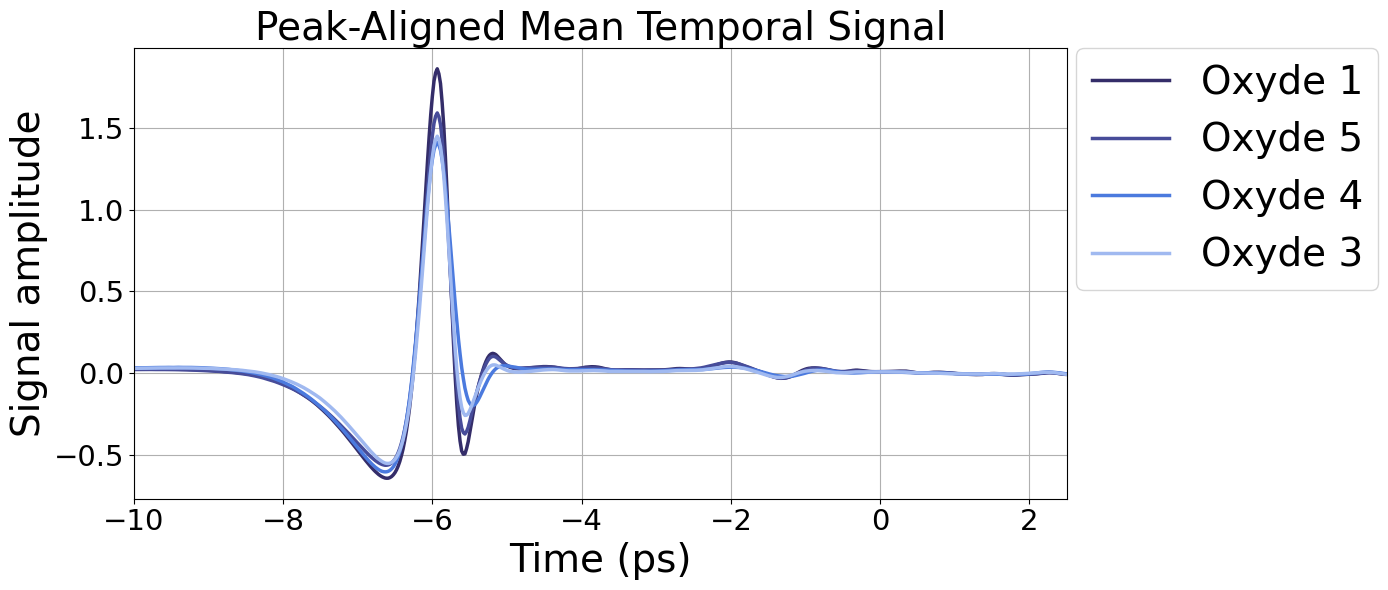

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

dt_ps = 0.020464 

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]
colors = [
    "#ba1b1b",  # 14_composite_20-percent_poro 0
    "#723834",  # 13_Oxyde-2_raw_no_porogene 1
    "#e67068",  # 12_Oxyde-2_no_porogene_20-percent_poro 2
    "#58190C",  # 11_Oxyde-7_porogene_pression-P2_with_porogene 3
    "#342D69",  # 1_Oxyde-1_no_porogene_0-percent_porosity 4
    "#9d2b14",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene 5
    "#8c2f00",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene 6
    "#ff5500",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene 7
    "#202245",  # 7_Oxyde-5_raw_no_porogene 8
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro 9
    "#213561",  # 5_Oxyde-4_raw_no_porogene 10
    "#4F5B76",  # 3_Oxyde-3_raw_no_porogene 11
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro 12
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus 13
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity 14
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder 15
]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
labels = ['Oxyde 1', 'Oxyde 5', 'Oxyde 4', 'Oxyde 3']
# sample_list = [4,0, 2, 5, 7] # Heatd internal porosity and porogene changes
# sample_list = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 11, 14] # Heatd vs raw

mean_signals = []
for i in sample_list:
    signals = ROI_arr[i].reshape(-1, T)

    signals_aligned = []
    cpt = 0

    max_sample = np.argmax(signals.max(axis=1))
    ref_peak = np.argmax(signals[max_sample])
    ref_max = np.max(signals[max_sample])
    
    for signal in signals : 
        shift = ref_peak - np.argmax(signal)
        max = np.max(signal)

        if max > 0.8*ref_max and max < 1.2*ref_max:
            signals_aligned.append(np.roll(signal, shift))
    
        cpt +=1
    signals_aligned = np.array(signals_aligned)
    mean_signals.append(signals_aligned.mean(axis=0))

mean_signals = np.array(mean_signals)

t = np.arange(T)*dt_ps

plt.figure(figsize=(14, 6))

# Adding the reference to the plot
path = r'\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CSV_files'

ref = np.loadtxt(path+r'\reference.csv', delimiter=',')
time_axis = np.loadtxt(path+r'\time_axis.csv', delimiter=',')

# plt.plot(time_axis, ref, '--', color='black', linewidth=1.5, label='Ref')

ref_peak = np.argmax(ref)

cpt = 0
for i in sample_list:
    color = colors[i]
    label = file_list[i].split("\\")[-1]

    # Re-compute std on the aligned pixel-level signals for the variance band
    shift = ref_peak - np.argmax(mean_signals[cpt])
    mean_signal = np.roll(mean_signals[cpt], shift, axis=0)
    std_signal = signals_aligned.std(axis=0)

    plt.plot(time_axis, mean_signal, color=color, linewidth=2.5, label=labels[cpt])
    # plt.fill_between(t,
    #                  mean_signal - std_signal,
    #                  mean_signal + std_signal,
    #                  color=color, alpha=0.25)
    
    cpt +=1

# Global mean across all aligned sample means
# global_mean = aligned_signals.mean(axis=0)
# plt.plot(t, global_mean, color='black', linewidth=2,
#          linestyle='--', label='Global mean (aligned)')

# plt.axvline(ref_peak, color='grey', linestyle=':', linewidth=1.2,
#             label=f'Ref peak (t={ref_peak})')

FONT_SIZE=28
plt.title("Peak-Aligned Mean Temporal Signal", fontsize=FONT_SIZE)
plt.xlabel("Time (ps)", fontsize=FONT_SIZE)
plt.ylabel("Signal amplitude", fontsize=FONT_SIZE)
plt.legend(fontsize=28, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
plt.tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.75)
plt.tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.75)
plt.tight_layout()
# plt.xlim([time_axis.min(), time_axis.max()])
plt.xlim([-10,2.5])
plt.grid()
plt.show()
# ── 4. Sanity-check: print shift applied to each sample ─────────────────────
# print(f"Reference peak index : {ref_peak}")
# for i in range(n_samples):
#     label = file_list[i].split("\\")[-1]
#     shift = ref_peak - peak_indices[i]
#     print(f"  {label:40s}  peak @ {peak_indices[i]:4d}  →  shift {shift:+d}")

In [15]:
%matplotlib inline

In [18]:
n = 1.45
t = 223e-12
c = 3e8

d= (c*t)/(2*n)
print(f"Higher estimation: {d*1e3} mm")

n = 2.7
t = 220e-12
c = 3e8

d= (c*t)/(2*n)
print(f"Lower estimation: {d*1e3} mm")

Higher estimation: 23.06896551724138 mm
Lower estimation: 12.222222222222221 mm


In [36]:
%matplotlib qt

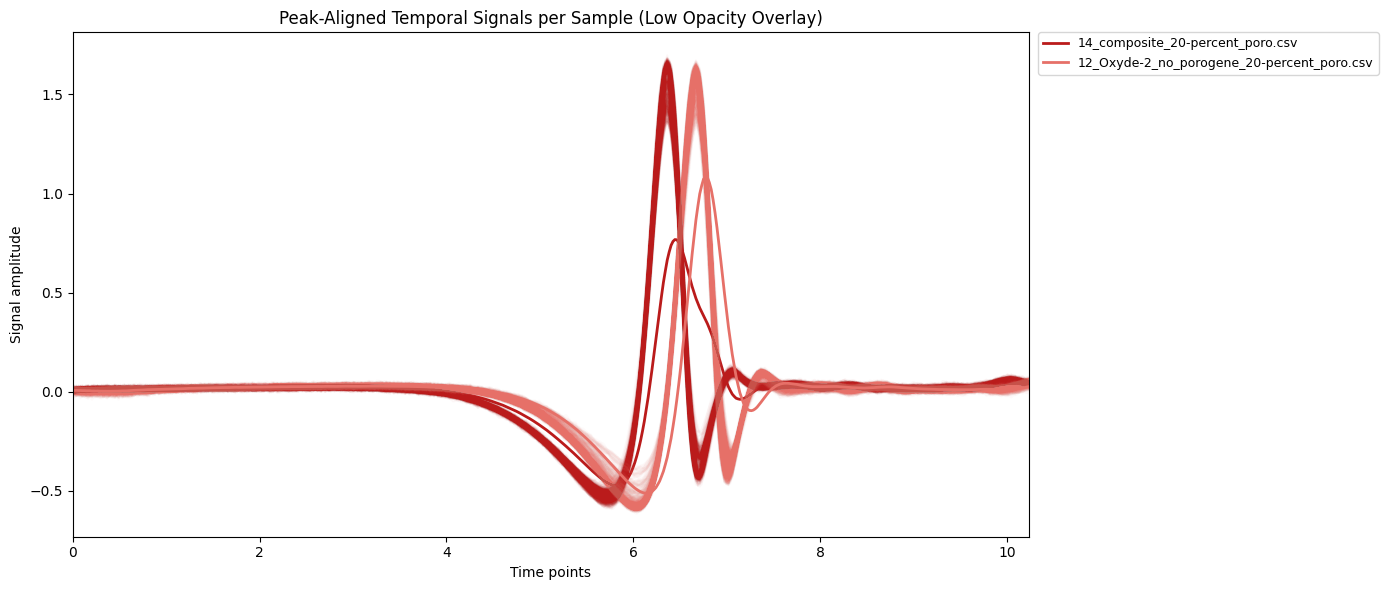

In [15]:
plt.figure(figsize=(14, 6))

colors = [
    "#ba1b1b",  # 14_composite_20-percent_poro 0
    "#723834",  # 13_Oxyde-2_raw_no_porogene 1
    "#e67068",  # 12_Oxyde-2_no_porogene_20-percent_poro 2
    "#58190C",  # 11_Oxyde-7_porogene_pression-P2_with_porogene 3
    "#342D69",  # 1_Oxyde-1_no_porogene_0-percent_porosity 4
    "#9d2b14",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene 5
    "#8c2f00",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene 6
    "#ff5500",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene 7
    "#202245",  # 7_Oxyde-5_raw_no_porogene 8
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro 9
    "#213561",  # 5_Oxyde-4_raw_no_porogene 10
    "#4F5B76",  # 3_Oxyde-3_raw_no_porogene 11
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro 12
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus 13
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity 14
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder 15
]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
sample_list = [0, 2, 5, 7 ] # Heatd internal porosity and porogene changes
sample_list = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 11, 14] # Heatd vs raw

for i in [0,2]: #sample_list:
    color = colors[i]
    
    signals = ROI_arr[i].reshape(-1, T)      # (225, T)
    label    = file_list[i].split("\\")[-1]
    
    signals_aligned = []
    cpt = 0

    max_sample = np.argmax(signals.max(axis=1))
    ref_peak = np.argmax(signals[max_sample])
    ref_max = np.max(signals[max_sample])
    
    for signal in signals : 
        shift = ref_peak - np.argmax(signal)
        max = np.max(signal)

        if max > 0.8*ref_max and max < 1.2*ref_max:
            signals_aligned.append(np.roll(signal, shift))
    
        cpt +=1
    signals_aligned = np.array(signals_aligned)

    # signals_aligned = np.roll(signals, shift, axis=1)     # (225, T)

    # All pixel signals – low opacity density cloud
    plt.plot(t, signals_aligned.T, color=color, alpha=0.03)

    # Aligned mean overlay
    mean_aligned = signals.mean(axis=0)
    plt.plot(t, mean_aligned, color=color, linewidth=2, label=label)

# Reference peak marker
# plt.axvline(ref_peak, color='grey', linestyle=':', linewidth=1.2,
#             label=f'Ref peak (t={ref_peak})')

plt.title("Peak-Aligned Temporal Signals per Sample (Low Opacity Overlay)")
plt.xlabel("Time points")
plt.ylabel("Signal amplitude")
plt.legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
plt.xlim([0,500*dt_ps])
plt.tight_layout()
plt.show()

# <span style="font-size: 35px"> <strong>Study 2:</strong> First peak metrics value comparison

C:\Users\hcherid\AppData\Local\Temp\ipykernel_17272\594902579.py:151: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


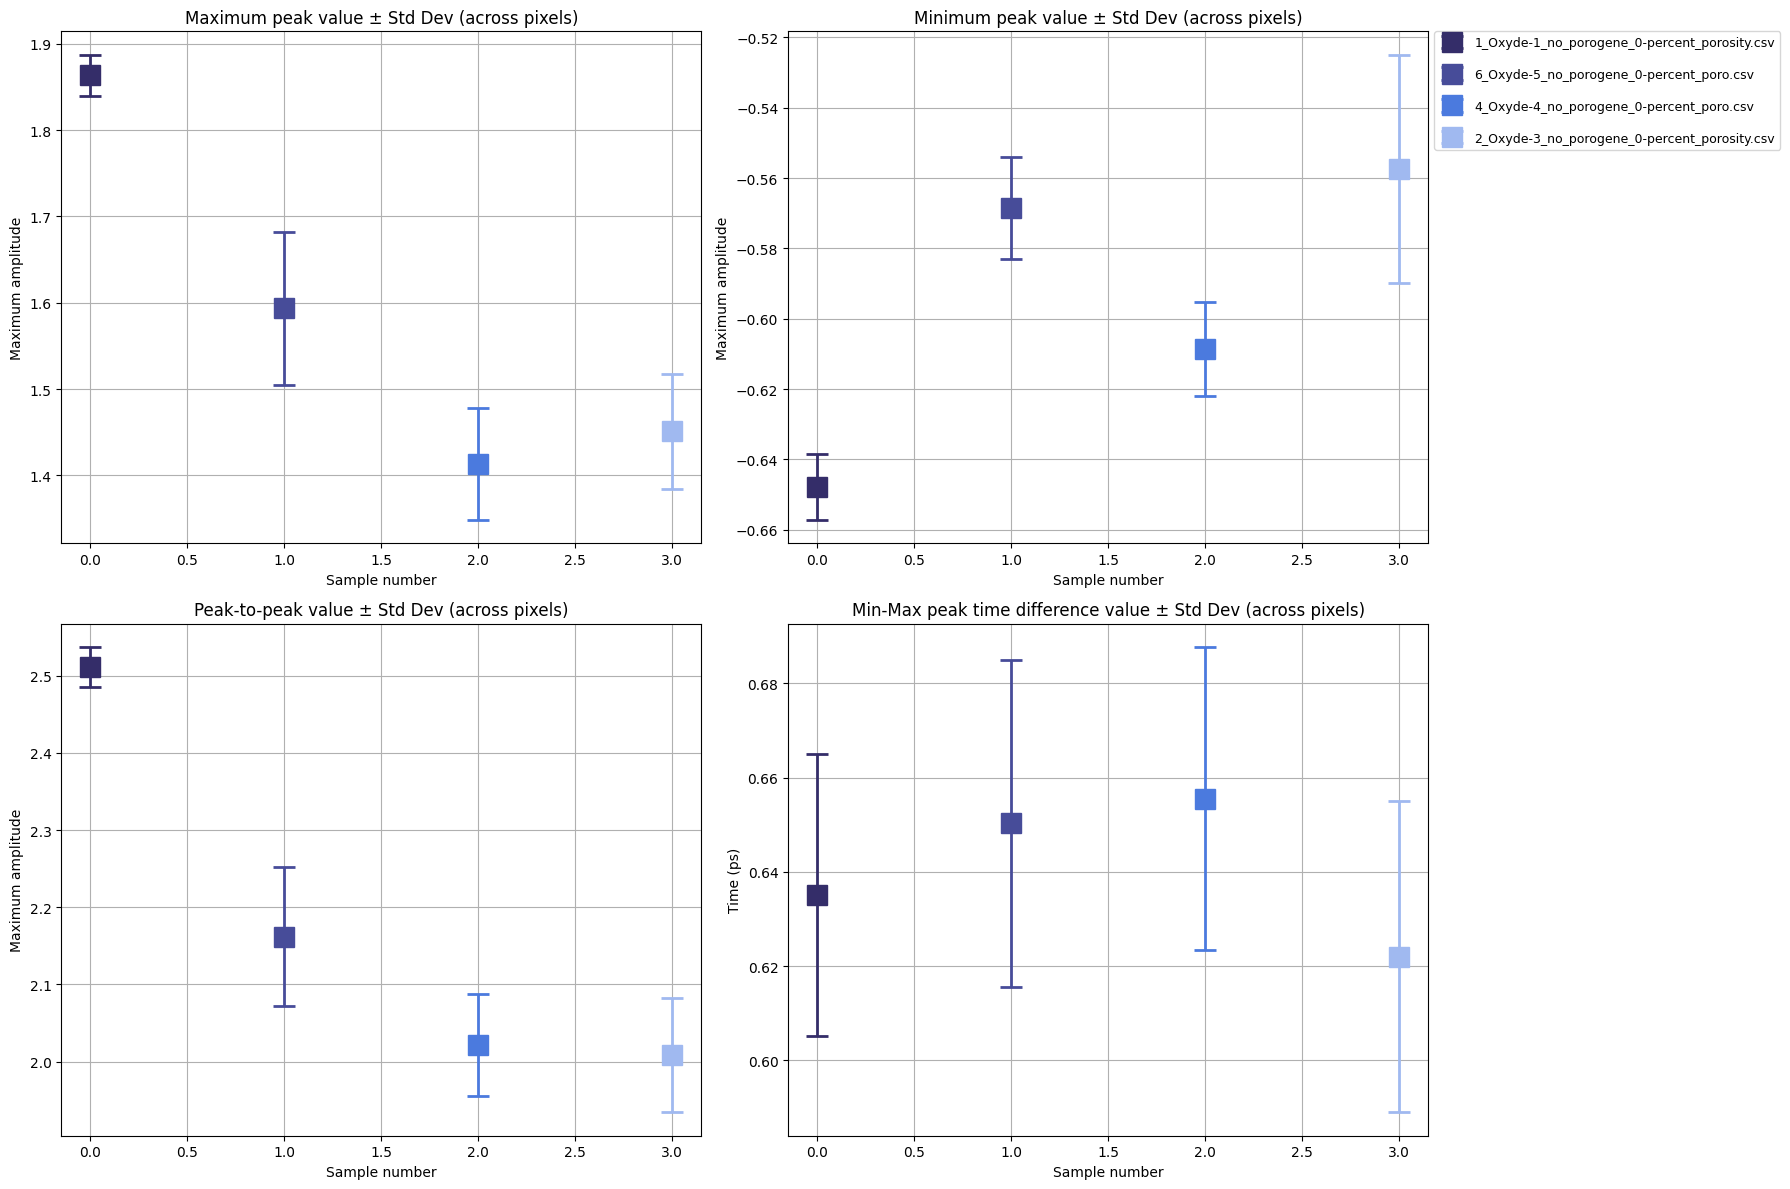

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]
colors = [
    "#ba1b1b",  # 14_composite_20-percent_poro 0
    "#723834",  # 13_Oxyde-2_raw_no_porogene 1
    "#e67068",  # 12_Oxyde-2_no_porogene_20-percent_poro 2
    "#58190C",  # 11_Oxyde-7_porogene_pression-P2_with_porogene 3
    "#342D69",  # 1_Oxyde-1_no_porogene_0-percent_porosity 4
    "#9d2b14",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene 5
    "#8c2f00",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene 6
    "#ff5500",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene 7
    "#202245",  # 7_Oxyde-5_raw_no_porogene 8
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro 9
    "#213561",  # 5_Oxyde-4_raw_no_porogene 10
    "#4F5B76",  # 3_Oxyde-3_raw_no_porogene 11
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro 12
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus 13
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity 14
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder 15
]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
# sample_list = [0, 2, 5, 7, 4] # Heatd internal porosity and porogene changes
# sample_list = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 11, 14] # Heatd vs raw

dt_ps = 0.020464 

fig, ax = plt.subplots(2,2,figsize=(18, 12))

cpt = 0
for i in sample_list:
    color = colors[i]
    label = file_list[i].split("\\")[-1]

    signals = ROI_arr[i].reshape(-1, T)

    max_sample = np.argmax(signals.max(axis=1))
    ref_max = np.max(signals[max_sample])

    max_values = []
    min_values = []

    Dt_values = []

    for signal in signals : 

        max = np.max(signal)
        min = np.min(signal)
        argmax = np.argmax(signal)
        argmin = np.argmin(signal)

        if max > 0.8*ref_max and max < 1.2*ref_max:
            max_values.append(max)
            min_values.append(min)
            Dt_values.append(dt_ps * (argmax - argmin))

    max_values = np.array(max_values)
    min_values = np.array(min_values)
    Dt_values = np.array(Dt_values)

    max_mean      = max_values.mean()
    max_std       = max_values.std()

    ax[0,0].errorbar(
        cpt, max_mean,
        yerr=max_std,
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    min_mean      = min_values.mean()
    min_std       = min_values.std()

    ax[0,1].errorbar(
        cpt, min_mean,
        yerr=min_std,
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    ax[1,0].errorbar(
        cpt, max_mean - min_mean,
        yerr=np.sqrt(min_std**2 + max_std**2),
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    Dt_mean      = Dt_values.mean()
    Dt_std       = Dt_values.std()

    ax[1,1].errorbar(
        cpt, Dt_mean,
        yerr=Dt_std,
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    cpt +=1

ax[0,0].set_title("Maximum peak value ± Std Dev (across pixels)")
ax[0,0].set_xlabel("Sample number")
ax[0,0].set_ylabel("Maximum amplitude")
ax[0,0].grid()

ax[0,1].set_title("Minimum peak value ± Std Dev (across pixels)")
ax[0,1].set_xlabel("Sample number")
ax[0,1].set_ylabel("Maximum amplitude")
ax[0,1].grid()

ax[1,0].set_title("Peak-to-peak value ± Std Dev (across pixels)")
ax[1,0].set_xlabel("Sample number")
ax[1,0].set_ylabel("Maximum amplitude")
ax[1,0].grid()

ax[1,1].set_title("Min-Max peak time difference value ± Std Dev (across pixels)")
ax[1,1].set_xlabel("Sample number")
ax[1,1].set_ylabel("Time (ps)")
ax[1,1].grid()

ax[0,1].legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0, labelspacing=1.5)
plt.tight_layout()

fig.show()

12 4


C:\Users\hcherid\AppData\Local\Temp\ipykernel_12396\1755849585.py:230: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


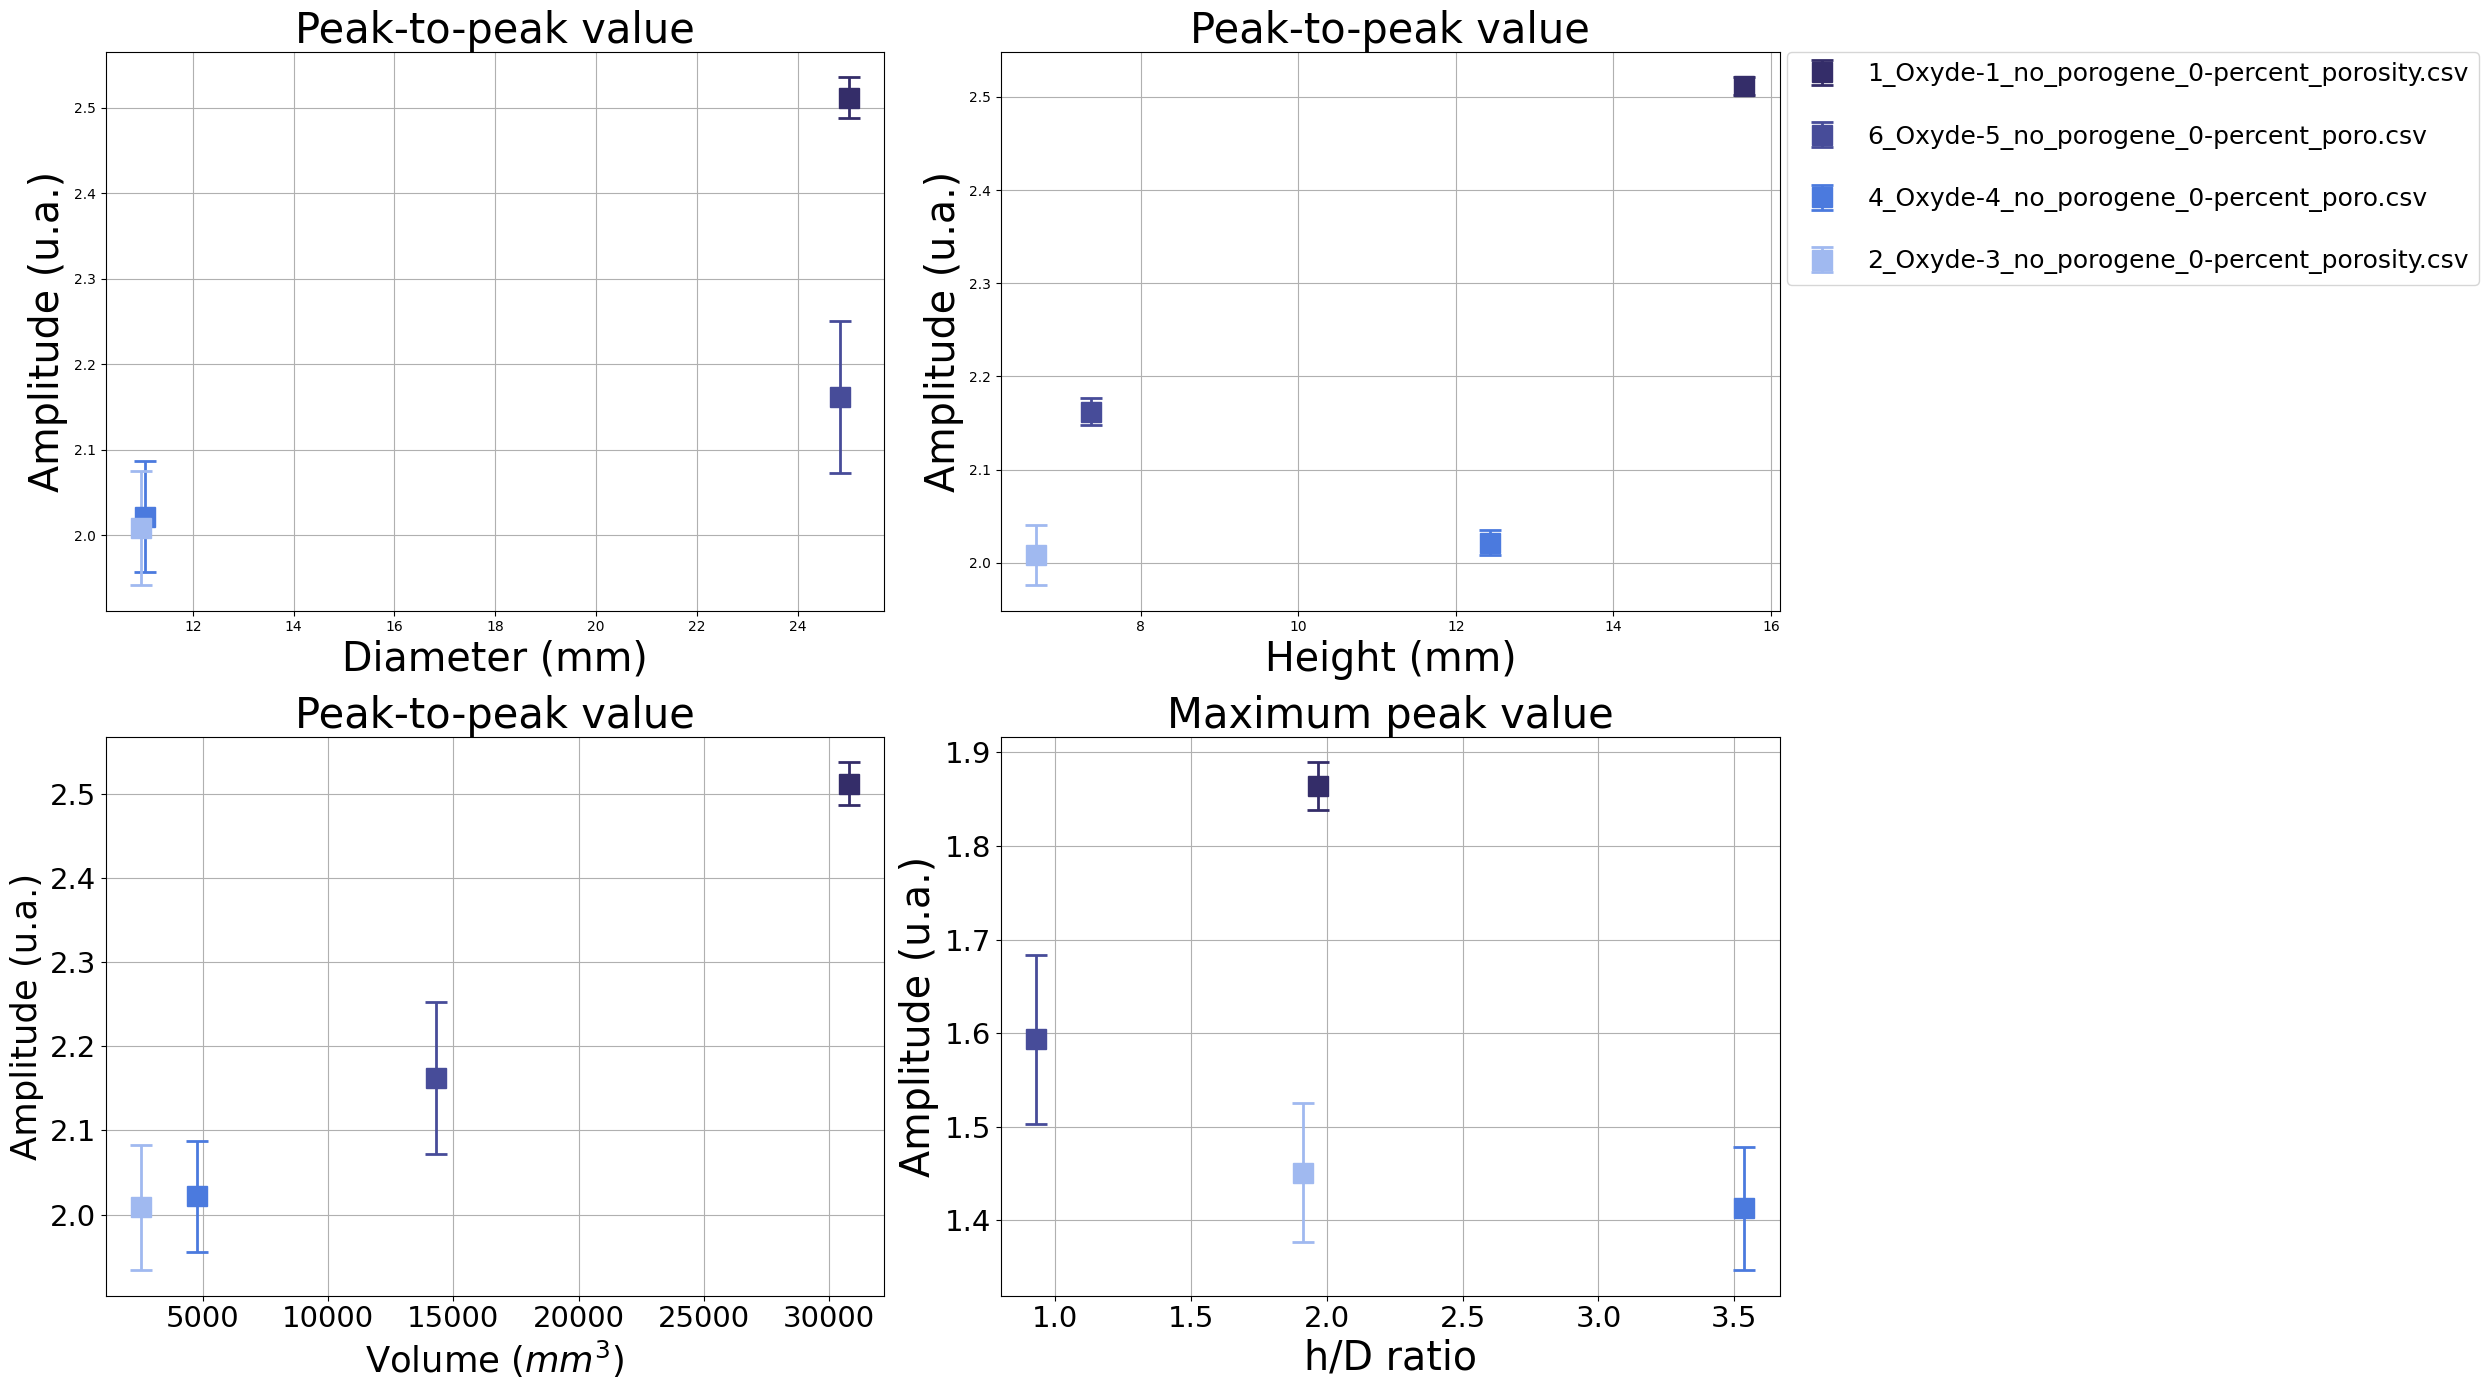

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]
colors = [
    "#ba1b1b",  # 14_composite_20-percent_poro 0
    "#723834",  # 13_Oxyde-2_raw_no_porogene 1
    "#e67068",  # 12_Oxyde-2_no_porogene_20-percent_poro 2
    "#58190C",  # 11_Oxyde-7_porogene_pression-P2_with_porogene 3
    "#342D69",  # 1_Oxyde-1_no_porogene_0-percent_porosity 4
    "#9d2b14",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene 5
    "#8c2f00",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene 6
    "#ff5500",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene 7
    "#202245",  # 7_Oxyde-5_raw_no_porogene 8
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro 9
    "#213561",  # 5_Oxyde-4_raw_no_porogene 10
    "#4F5B76",  # 3_Oxyde-3_raw_no_porogene 11
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro 12
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus 13
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity 14
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder 15
]

diameter = [1, 11.88, 11.88, 25.02, 25.02, 25.02, 24.86, 24.86, 24.85, 24.85, 11.05, 10.97, 11.05, 10.97, 10.97, 25.02]
height = [1, 9.37, 9.37, 7.80, 15.66, 7.80, 7.2, 7.2, 7.37, 7.37, 12.44, 6.68, 12.44, 6.68, 6.68, 15.66]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
# sample_list = [0, 2, 5, 7, 4] # Heatd internal porosity and porogene changes
# sample_list = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 11, 14] # Heatd vs raw
# sample_list = [4,3,5,6,7,8,9]

space = 7
d = 1
sample_x_axis = [0,d, space, space+d, space*2, space*2 + d, space*3, space*3 + d, space*4, space*4 + d, space*5, space*5 + d]
print(len(sample_x_axis), len(sample_list))

dt_ps = 0.020464 

fig, ax = plt.subplots(2,2,figsize=(25, 14))

cpt = 0
for i in sample_list:

    color = colors[i]
    label = file_list[i].split("\\")[-1]

    signals = ROI_arr[i].reshape(-1, T)

    max_sample = np.argmax(signals.max(axis=1))
    ref_max = np.max(signals[max_sample])

    max_values = []
    min_values = []

    Dt_values = []

    for signal in signals : 

        max = np.max(signal)
        min = np.min(signal)
        argmax = np.argmax(signal)
        argmin = np.argmin(signal)

        if max > 0.8*ref_max and max < 1.2*ref_max:
            max_values.append(max)
            min_values.append(min)
            Dt_values.append(dt_ps * (argmax - argmin))

    max_values = np.array(max_values)
    min_values = np.array(min_values)
    Dt_values = np.array(Dt_values)

    max_mean      = max_values.mean()
    max_std       = max_values.std()

    min_mean      = min_values.mean()
    min_std       = min_values.std()

    ax[0,0].errorbar(
        diameter[i], max_mean - min_mean,
        yerr=max_std,
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    ax[0,1].errorbar(
        height[i], max_mean - min_mean,
        yerr=min_std,
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    ax[1,0].errorbar(
        np.pi * height[i] * diameter[i]**2, max_mean - min_mean,
        yerr=np.sqrt(min_std**2 + max_std**2),
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    # Max peak against height / diameter ratio
    ax[1,1].errorbar(
            np.pi * height[i] / diameter[i], max_mean,
            yerr=np.sqrt(min_std**2 + max_std**2),
            fmt='s',                  
            markersize=15,
            color=color,
            ecolor=color,             
            elinewidth=2,             
            capsize=8,                
            capthick=2,               
            label=label
        )

    # Maximum peak value against volume
    # ax[1,1].errorbar(
    #     np.pi * height[i] * diameter[i]**2, max_mean,
    #     yerr=np.sqrt(min_std**2 + max_std**2),
    #     fmt='s',                  
    #     markersize=15,
    #     color=color,
    #     ecolor=color,             
    #     elinewidth=2,             
    #     capsize=8,                
    #     capthick=2,               
    #     label=label
    # )

    # peak to peak afainst sample number
    # ax[1,1].errorbar(
    #     sample_x_axis[cpt], max_mean - min_mean,
    #     yerr=np.sqrt(min_std**2 + max_std**2),
    #     fmt='s',                  
    #     markersize=15,
    #     color=color,
    #     ecolor=color,             
    #     elinewidth=2,             
    #     capsize=8,                
    #     capthick=2,               
    #     label=label
    # )

    Dt_mean      = Dt_values.mean()
    Dt_std       = Dt_values.std()

    # ax[1,1].errorbar(
    #     cpt, Dt_mean,
    #     yerr=Dt_std,
    #     fmt='s',                  
    #     markersize=15,
    #     color=color,
    #     ecolor=color,             
    #     elinewidth=2,             
    #     capsize=8,                
    #     capthick=2,               
    #     label=label
    # )

    cpt +=1

FONT_SIZE = 30

ax[0,0].set_title("Peak-to-peak value", fontsize = FONT_SIZE)
ax[0,0].set_xlabel("Diameter (mm)", fontsize = FONT_SIZE*0.95)
ax[0,0].set_ylabel("Amplitude (u.a.)", fontsize = FONT_SIZE*0.95)
ax[0,0].grid()

ax[0,1].set_title("Peak-to-peak value", fontsize = FONT_SIZE)
ax[0,1].set_xlabel("Height (mm)", fontsize = FONT_SIZE*0.95)
ax[0,1].set_ylabel("Amplitude (u.a.)", fontsize = FONT_SIZE*0.95)
ax[0,1].grid()

ax[1,0].set_title("Peak-to-peak value", fontsize = FONT_SIZE)
ax[1,0].set_xlabel("Volume ($mm^3$)", fontsize = FONT_SIZE*0.85)
ax[1,0].set_ylabel("Amplitude (u.a.)", fontsize = FONT_SIZE*0.85)
ax[1,0].tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.7)
ax[1,0].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.7)
ax[1,0].grid()

# Maximum peak value against height / diameter ratio
ax[1,1].set_title("Maximum peak value", fontsize = FONT_SIZE)
ax[1,1].set_xlabel("h/D ratio", fontsize = FONT_SIZE*0.95)
ax[1,1].set_ylabel("Amplitude (u.a.)", fontsize = FONT_SIZE*0.95)
ax[1,1].tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.7)
ax[1,1].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.7)
ax[1,1].grid()

# Maximum peak value against volume
# ax[1,1].set_title("Maximum peak value", fontsize = FONT_SIZE)
# ax[1,1].set_xlabel("Volume ($mm^3$)", fontsize = FONT_SIZE*0.95)
# ax[1,1].set_ylabel("Amplitude", fontsize = FONT_SIZE*0.95)
# ax[1,1].tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.7)
# ax[1,1].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.7)
# ax[1,1].grid()

# Peak to peak value against sample number
# ax[1,1].set_title("Peak-to-peak value", fontsize = FONT_SIZE)
# # ax[1,1].set_xlabel("Volume ($mm^3$)", fontsize = FONT_SIZE*0.95)
# ax[1,1].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.7)
# ax[1,1].set_ylabel("Amplitude", fontsize = FONT_SIZE*0.95)
# ax[1,1].grid()

# ax[1,1].set_title("Min-Max peak time difference value ± Std Dev (across pixels)")
# ax[1,1].set_xlabel("Sample number")
# ax[1,1].set_ylabel("Time (ps)")
# ax[1,1].grid()

ax[0,1].legend(fontsize=FONT_SIZE*0.6, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0, labelspacing=1.5)
plt.tight_layout()

fig.show()

# <span style="font-size: 35px"> <strong>Study 3:</strong> B-scans representation

C:\Users\hcherid\AppData\Local\Temp\ipykernel_12396\2260475461.py:66: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


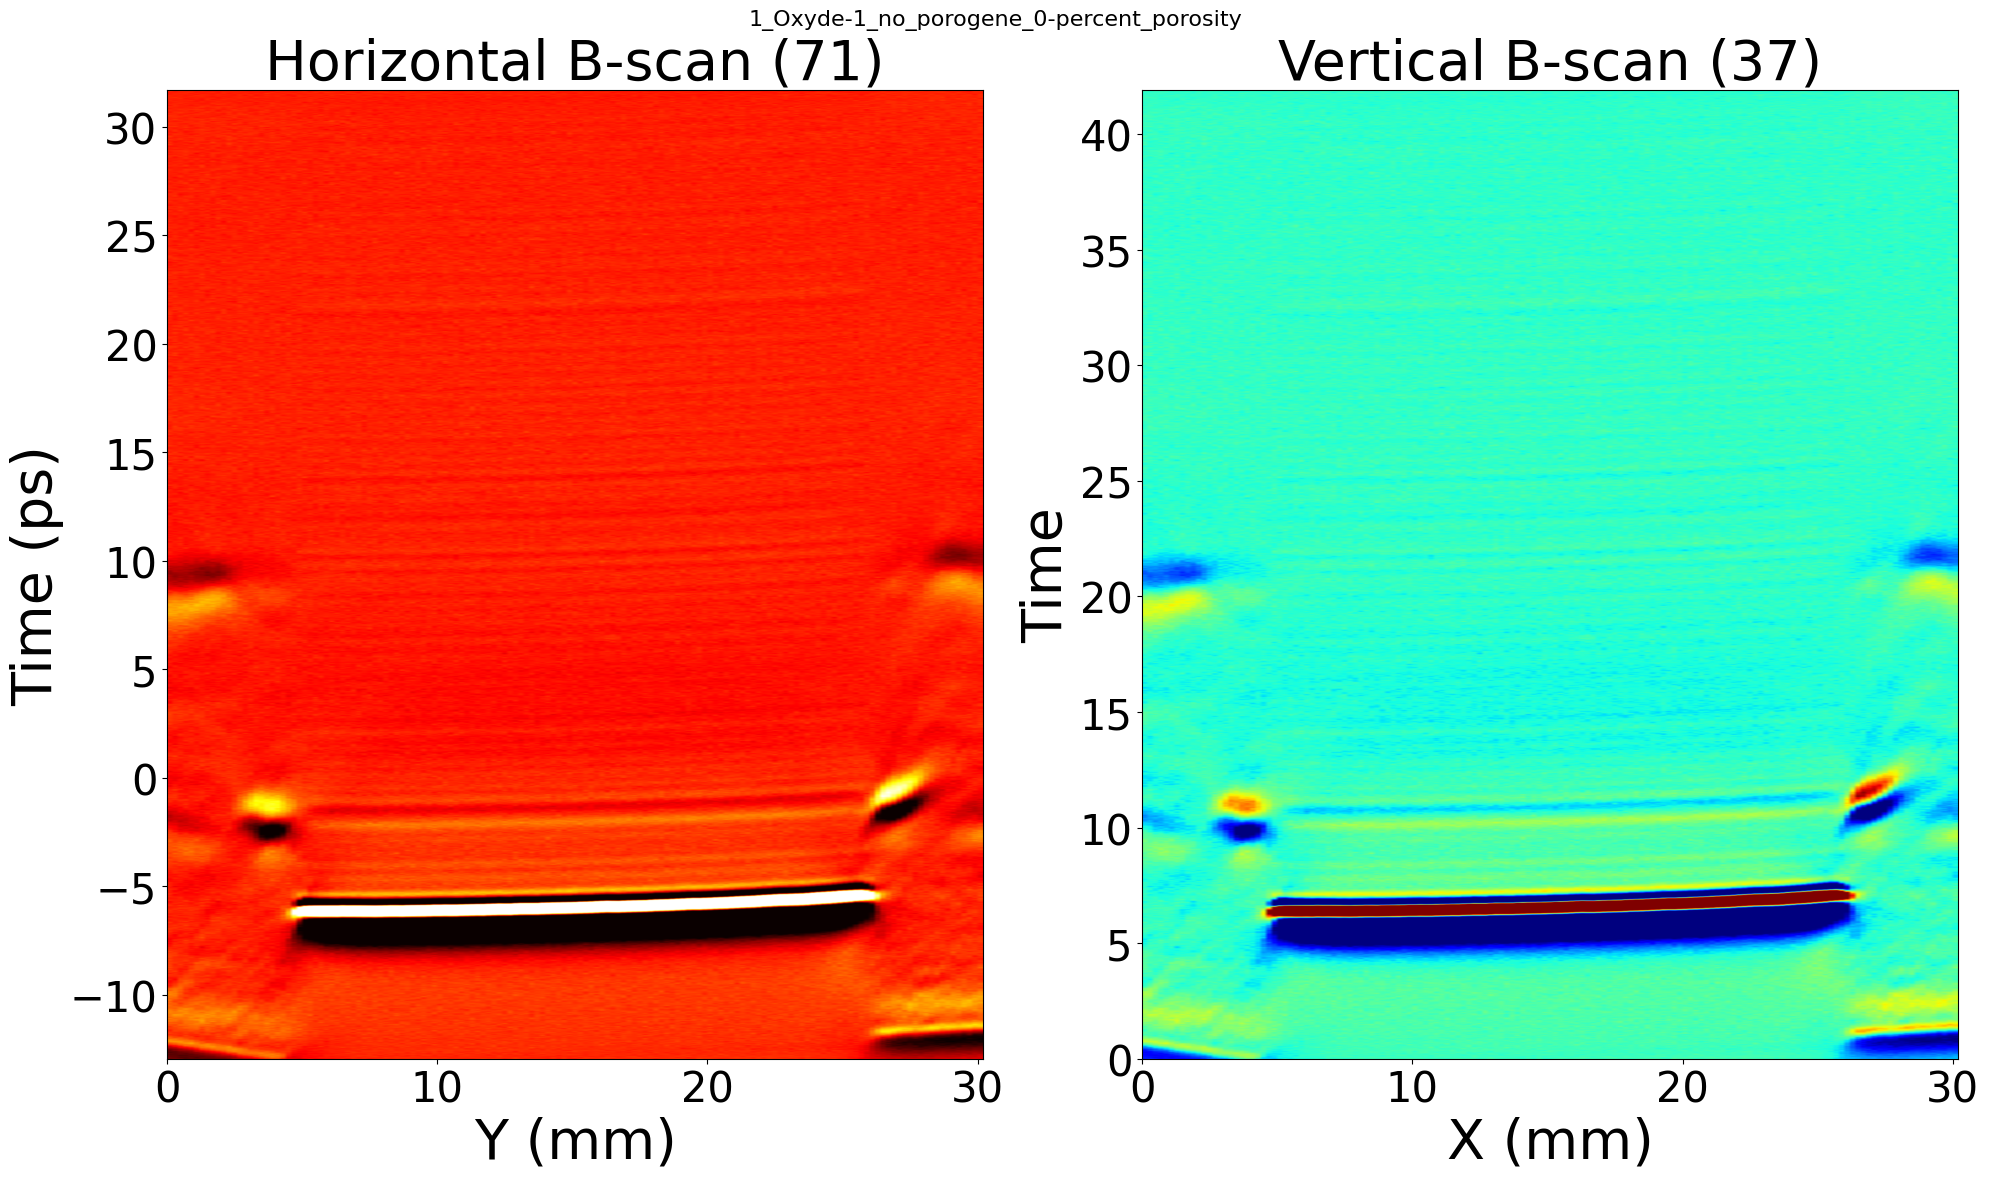

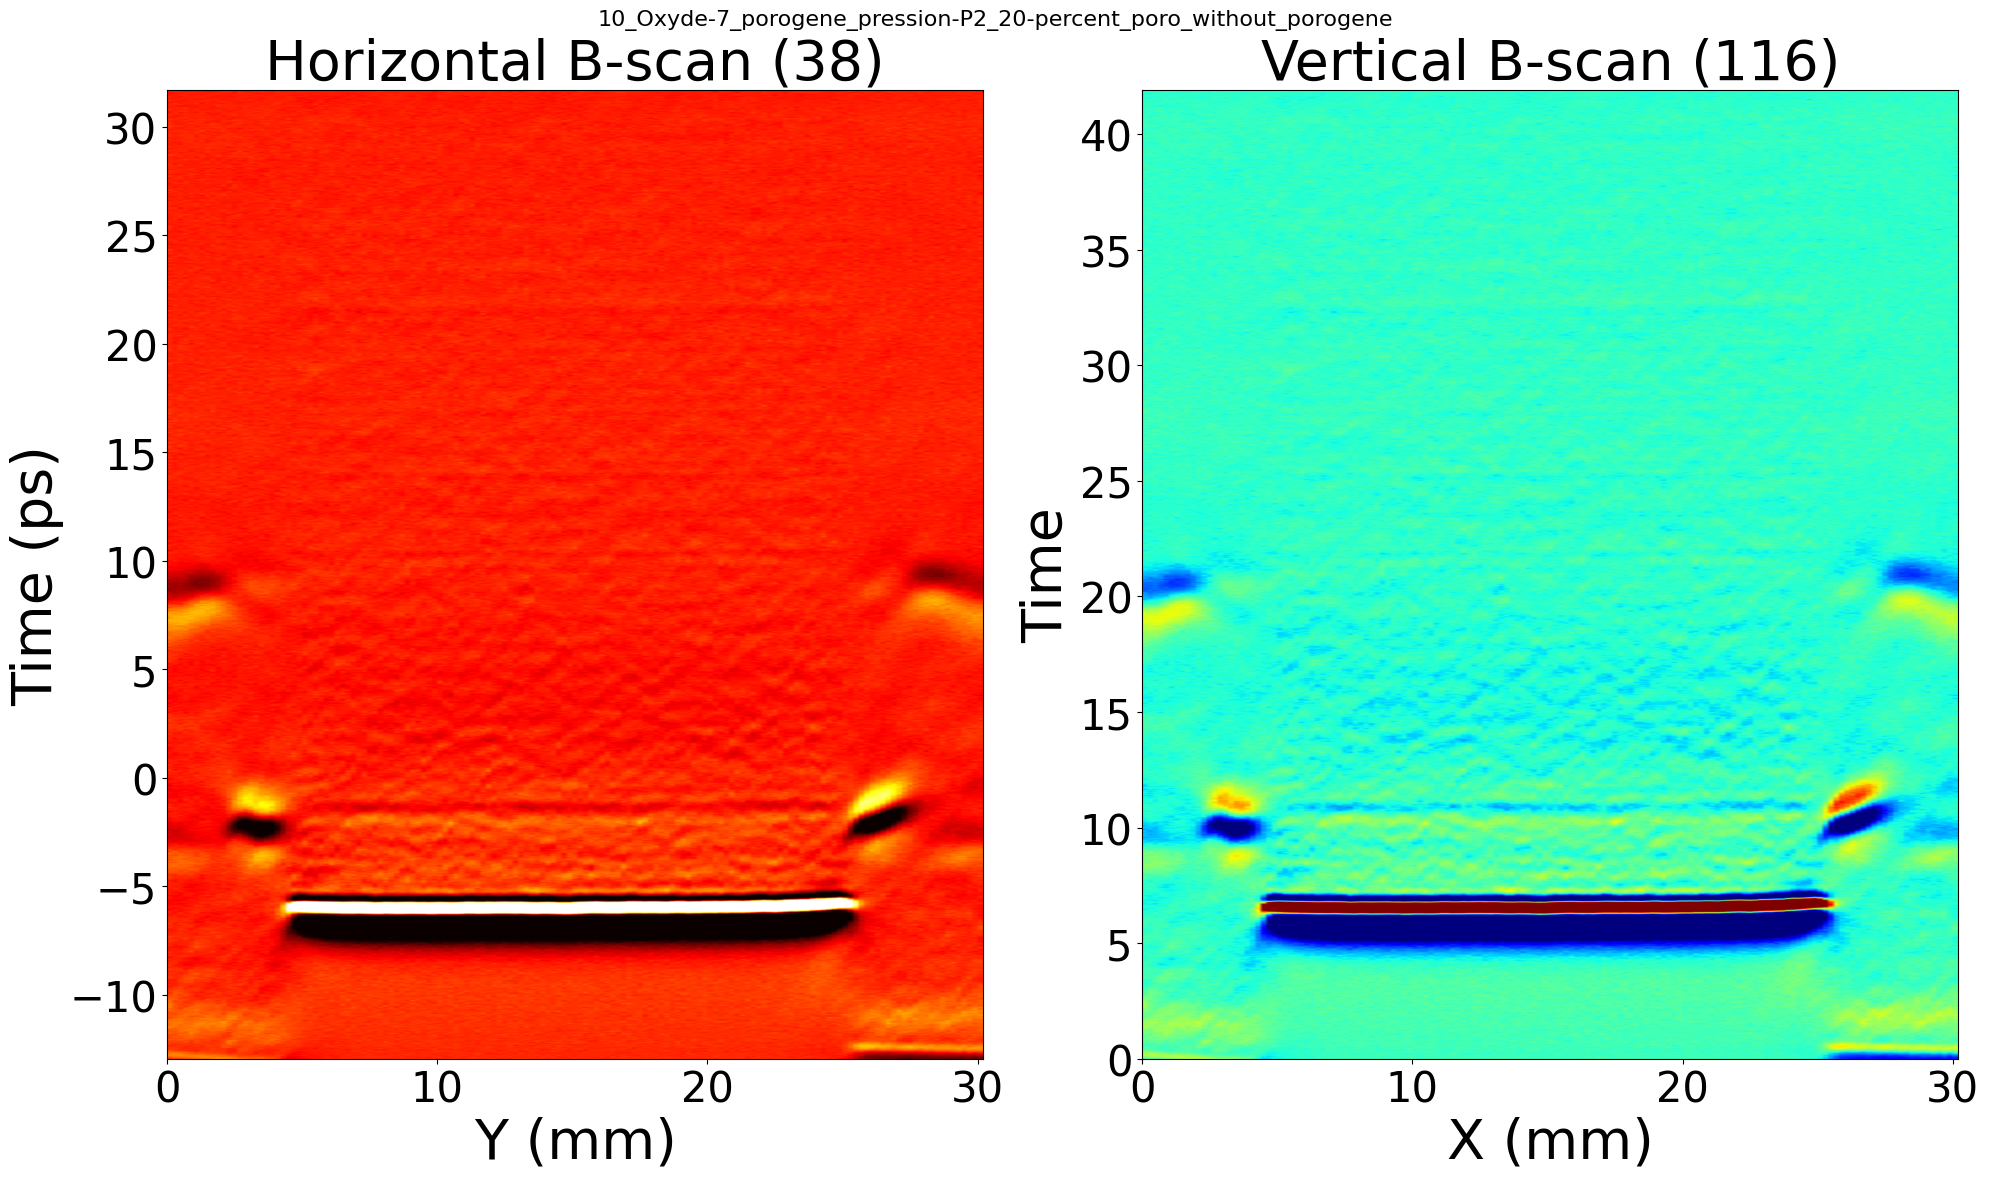

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.ticker import MultipleLocator
%matplotlib inline
dt_ps = 0.020464 

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
# sample_list = [0, 2, 5, 7,4] # Heatd internal porosity and porogene changes
# sample_list = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 11, 14] # Raw vs Heated
sample_list = [4, 5]

vmin = -0.2
vmax = 0.3

step_mm = 0.2
dt_ps = 0.020464 

path = r'\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CSV_files'

ref = np.loadtxt(path+r'\reference.csv', delimiter=',')
time_axis = np.loadtxt(path+r'\time_axis.csv', delimiter=',')

for i in sample_list:

    signal_array = np.loadtxt(file_list[i], delimiter=',')
    signal_array = signal_array[:, :].T

    datacube = signal_array.reshape(x_shape_list[i][1], x_shape_list[i][0], 2048)

    coords = np.unravel_index(np.argmax(datacube), datacube.shape)

    vert_b_scan = datacube[:, datacube.shape[1]//2, :].T
    hor_b_scan = datacube[datacube.shape[0]//2, :, :].T

    FONT_SIZE = 40
    fig, ax = plt.subplots(1,2, figsize=(20,12))
    ax[0].imshow(vert_b_scan, cmap='hot', origin='lower', aspect='auto', vmin=vmin, vmax=vmax,
                 extent=[0, vert_b_scan.shape[1]*step_mm, time_axis[0], time_axis[-1]]) #extent=[x_axis_mm[0], x_axis_mm[-1], y_axis_mm[0], y_axis_mm[-1]])

    ax[0].set_title(f"Horizontal B-scan ({coords[1]})", fontsize=FONT_SIZE)
    ax[0].set_xlabel("Y (mm)", fontsize=FONT_SIZE)
    ax[0].set_ylabel("Time (ps)", fontsize=FONT_SIZE)
    ax[0].tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.75)
    ax[0].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.75)
    
    # plt.colorbar(label='Signal amplitude')

    ax[1].imshow(vert_b_scan, cmap='jet', origin='lower', aspect='auto', vmin=vmin, vmax=vmax,
                 extent=[0, vert_b_scan.shape[1]*step_mm, 0, vert_b_scan.shape[0]*dt_ps]) #extent=[x_axis_mm[0], x_axis_mm[-1], y_axis_mm[0], y_axis_mm[-1]])

    ax[1].set_title(f"Vertical B-scan ({coords[0]})", fontsize=FONT_SIZE)
    ax[1].set_xlabel("X (mm)", fontsize=FONT_SIZE)
    ax[1].set_ylabel("Time", fontsize=FONT_SIZE)
    ax[1].tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.75)
    ax[1].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.75)

    fig.suptitle(
        file_list[i].split("\\")[-1].removesuffix(".csv"),
        fontsize=16
    )
    fig.tight_layout()
    fig.show()

# <span style="font-size: 35px"> <strong>Study 4:</strong> 2D visualization of ROI on THz C-scans

  0%|          | 0/16 [00:00<?, ?it/s]C:\Users\Hugo\AppData\Local\Temp\ipykernel_57864\1132060099.py:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
  6%|▋         | 1/16 [00:02<00:44,  2.98s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\14_composite_20-percent_poro.csv
array shape: (13456, 2048)
[116 116] 13456
[116 116] 13456
Final datacube shape (x,y,time): (116, 116, 2048)


 12%|█▎        | 2/16 [00:04<00:27,  1.99s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\13_Oxyde-2_raw_no_porogene.csv
array shape: (5776, 2048)
[76 76] 5776
[76 76] 5776
Final datacube shape (x,y,time): (76, 76, 2048)


 19%|█▉        | 3/16 [00:05<00:21,  1.68s/it]

...

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\3_Oxyde-3_raw_no_porogene_no_focus.csv
array shape: (4941, 2048)
[81 61] 4941
[81 61] 4941
Final datacube shape (x,y,time): (61, 81, 2048)


 94%|█████████▍| 15/16 [00:47<00:01,  1.80s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\2_Oxyde-3_no_porogene_0-percent_porosity.csv
array shape: (4941, 2048)
[81 61] 4941
[81 61] 4941
Final datacube shape (x,y,time): (61, 81, 2048)


100%|██████████| 16/16 [00:53<00:00,  3.36s/it]

F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\1_Oxyde-1_no_porogene_0-percent_porosity_old_holder.csv
array shape: (27693, 2048)
[153 181] 27693
[153 181] 27693
Final datacube shape (x,y,time): (181, 153, 2048)


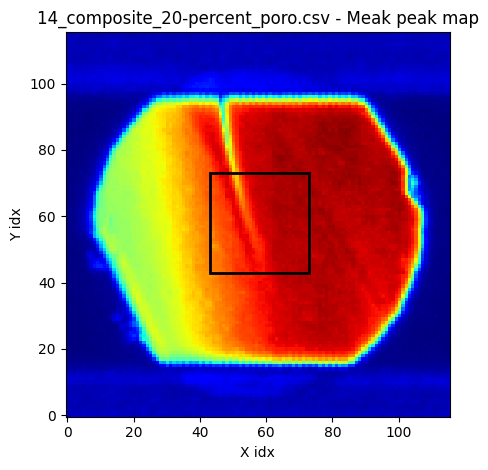

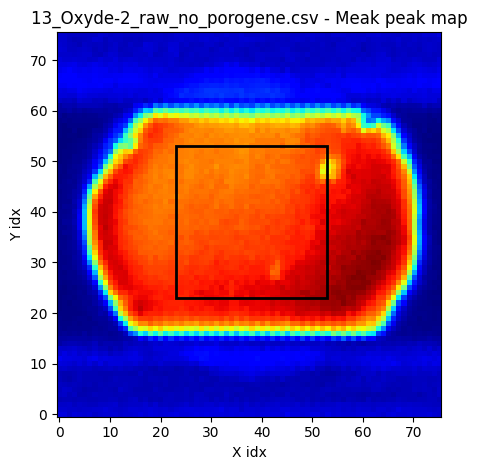

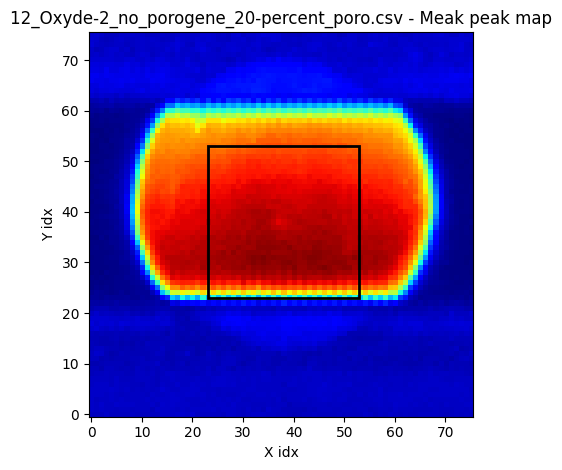

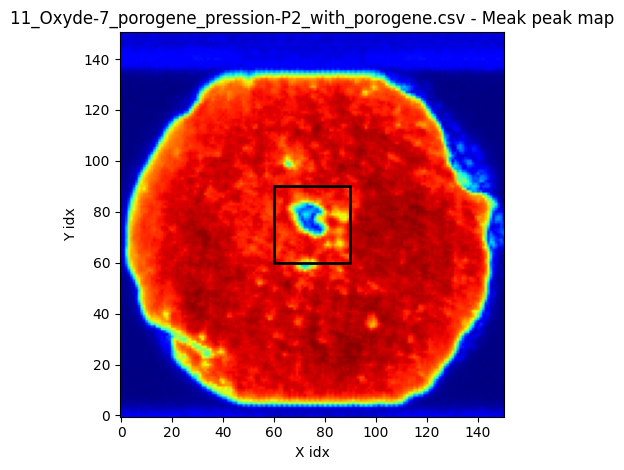

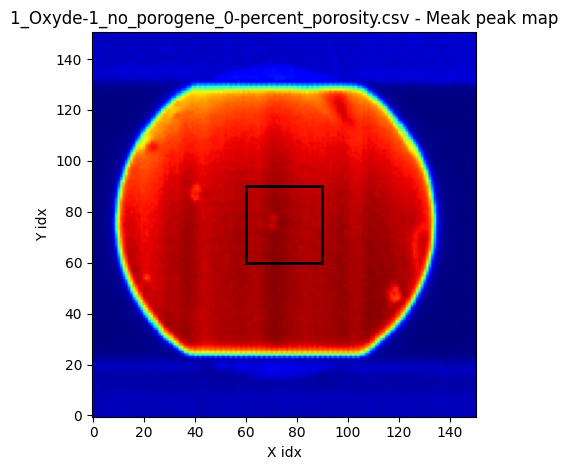

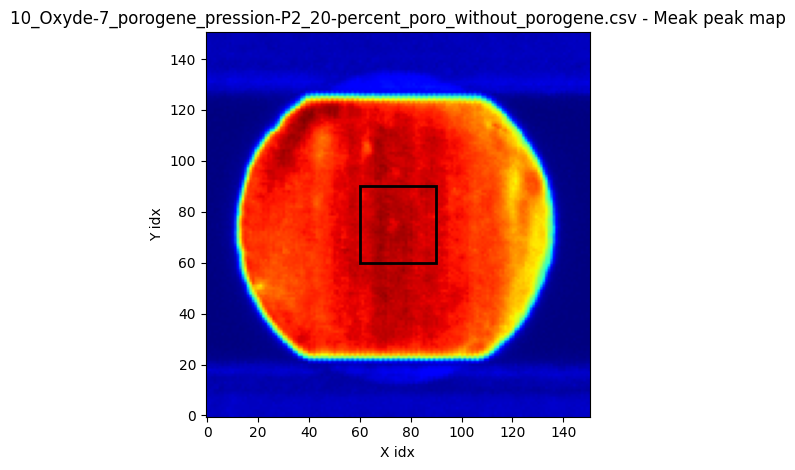

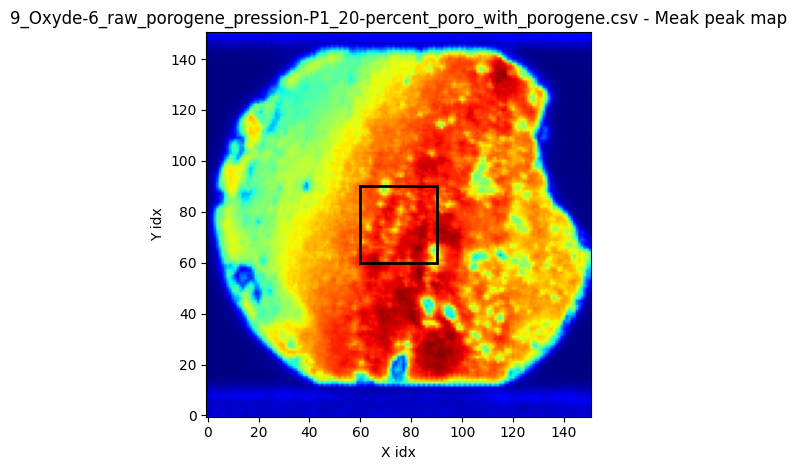

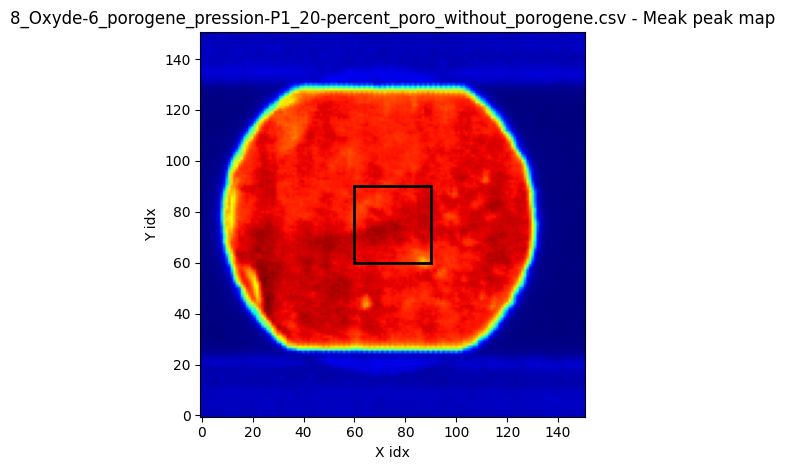

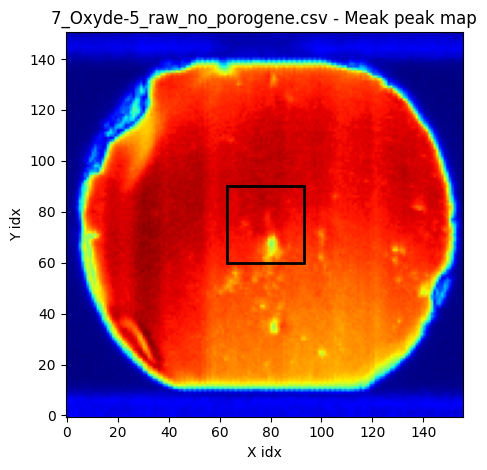

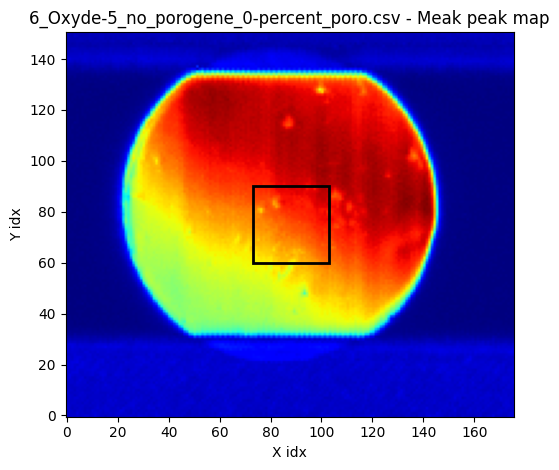

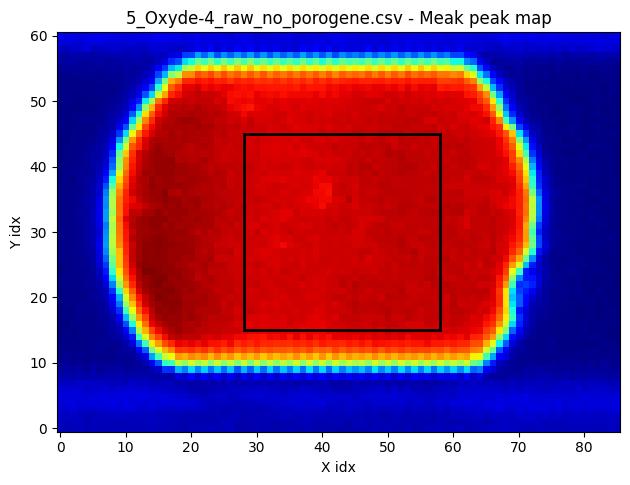

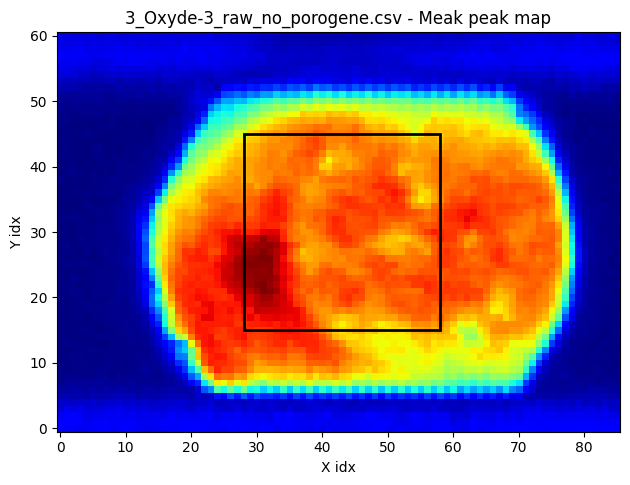

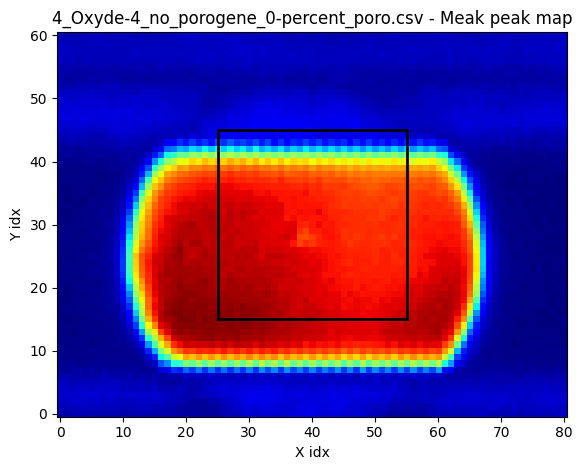

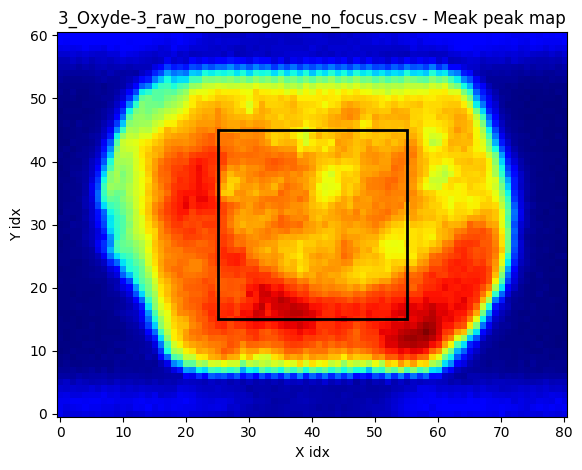

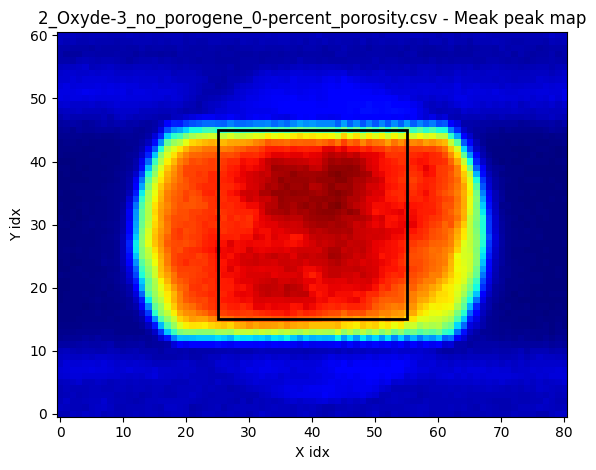

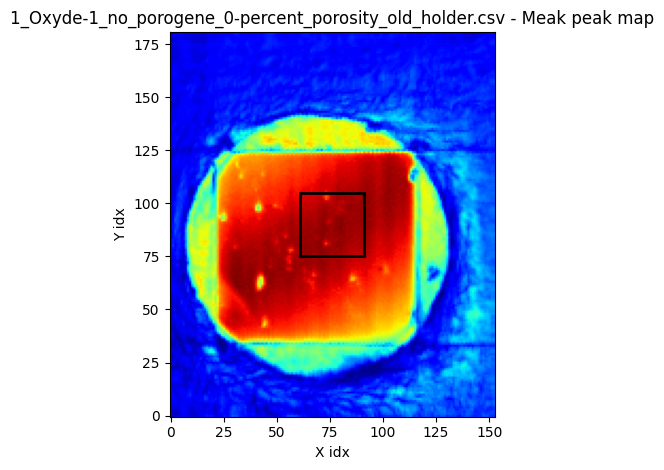

In [25]:
%matplotlib inline

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm

prefix_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
# prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

x_shape_list = np.load(fr"{prefix_path}/x_shape_list.npy")
y_shape_list = np.load(fr"{prefix_path}/y_shape_list.npy")
file_list = np.load(fr"{prefix_path}/file_list.npy")

ROI_list = []

X_ROI = 15
Y_ROI = 15

dt_ps = 0.020464 

save_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"
save = False

def show_maxpeak(center, w, h, file):
    cscan = np.max(datacube, axis = 2)

    # Flip data vertically to make origin at bottom left (test if this is correct, otherwise do not use!!)
    #cscan_flipped = np.flipud(cscan)

    fig, ax = plt.subplots()
    ax.imshow(cscan, cmap='jet', origin='lower') #extent=[x_axis_mm[0], x_axis_mm[-1], y_axis_mm[0], y_axis_mm[-1]])

    rect_ROI = patches.Rectangle(
        center, w, h,
        linewidth=2,
        edgecolor='black',
        facecolor='none'
    )

    ax.add_patch(rect_ROI)    

    ax.set_title(f"{file} - Meak peak map")
    ax.set_xlabel("X idx")
    ax.set_ylabel("Y idx")
    # plt.colorbar(label='Signal amplitude')
    fig.tight_layout()
    fig.show()

for idx in tqdm(range(len(file_list))):
    # loadi into numpy array
    signal_array = np.loadtxt(file_list[idx], delimiter=',')
    signal_array = signal_array[:, :].T

    # Show matrix size
    print(file_list[idx])
    print("array shape:", signal_array.shape)
    print(x_shape_list[idx], x_shape_list[idx][0]*x_shape_list[idx][1])
    print(y_shape_list[idx], y_shape_list[idx][0]*y_shape_list[idx][1])

    datacube = signal_array.reshape(x_shape_list[idx][1], x_shape_list[idx][0], 2048) # If using filtered signal
    # Check size
    print("Final datacube shape (x,y,time):", datacube.shape)

    ROI = datacube[datacube.shape[1]//2-X_ROI:datacube.shape[1]//2+X_ROI,
                datacube.shape[0]//2-Y_ROI:datacube.shape[0]//2+Y_ROI,
                :]
    
    num_y, num_x, num_timepoints = datacube.shape
    time_axis = np.arange(num_timepoints) * dt_ps

    center = (datacube.shape[1]//2-X_ROI, datacube.shape[0]//2-Y_ROI)
    time = 7

    show_maxpeak(center, X_ROI*2, Y_ROI*2, file_list[idx].split("\\")[-1])

    ROI_list.append(ROI)

ROI_arr = np.array(ROI_list)

if save:
    np.save(fr"{save_path}/ROI_arr", ROI_arr)


In [5]:
t = (22+6)*1e-12
n = 2.0
c = 3e8

d = (c*t)/(2*n)

print(d*1e3)

2.1
